# 07. Pollution Damage and Income Feedback

This notebook asks how pollutant-specific damage assumptions change current income, future income, and resources when pollution rises with an exogenous development path.

In [1]:
import copy
import pandas as pd
import matplotlib.pyplot as plt

from study_3_pollutant_dynamics.config import EnvironmentConfig
from study_3_pollutant_dynamics.environment import PollutantDynamicsEnvironment
from study_3_pollutant_dynamics.economic_parameters import (REGIONAL_ECONOMIC_PARAMETERS, REGIONAL_EMISSION_PROFILE_MULTIPLIERS,
                                                            STAGE_2_SCENARIOS)
from study_3_pollutant_dynamics.scenario_parameters import get_parameters
from study_3_pollutant_dynamics.damage_parameters import DAMAGE_SCENARIOS
from study_3_pollutant_dynamics.regional_economics import (calculate_annual_income, calculate_emission_activity_index)
from study_3_pollutant_dynamics.environmental_damage import (update_lagged_exposure, calculate_pollutant_damage_fractions,
                                                             combine_damage_fractions, apply_income_damage)

## Damage equations and timing

Each pollutant uses a separate pressure measure:
- PM2.5 excess above the region's exposure baseline
- lagged CO2 excess above the initial global concentration
- squared relative nitrate excess above the Keokuk reference concentration
- lagged relative mobile-lead increase above each parcel's initial condition.

Each damage fraction is `1 - exp(-pressure × rate)`, which stays between zero and one.

In [2]:
damage_parameter_rows = []

for scenario_name, settings in DAMAGE_SCENARIOS.items():
    row = {"scenario": scenario_name}

    for parameter_name, parameter_value in settings.items():
        row[parameter_name] = parameter_value
    damage_parameter_rows.append(row)

damage_parameter_table = pd.DataFrame(damage_parameter_rows)
display(damage_parameter_table.round(5))

,scenario,pm25_rate_per_ug_m3,co2_rate_per_ppm,nitrate_relative_rate,lead_relative_rate,co2_delay_years,lead_delay_years
0,low,0.001,0.00005,0.10,0.01,15.0,8.0
1,reference,0.002,0.00010,0.25,0.03,10.0,5.0
2,high,0.004,0.00020,0.50,0.06,5.0,2.0


## Coupled scenario test

The model runs 40 annual steps. EDI follows a fixed test path: no change, +1 point per year, or +2 points per year, capped at 100. The gross income calculation carries forward the prior year's net income before applying the current year's damage, so income losses reduce the base for later growth. EDI itself is exogenous here; this notebook does not model investment or spending choices.

In [3]:
def update_annual_emissions(config, year, edi_gain_per_year, initial_edi, reference_nitrate_inputs, reference_lead_inputs):
    current_edi = []
    edi_activity_factors = []
    edi_income_factors = []

    emission_elasticity = STAGE_2_SCENARIOS["emission_edi_elasticity"]["reference"]
    income_elasticity = STAGE_2_SCENARIOS["income_edi_elasticity"]["reference"]

    for region_index in range(len(config.regions)):
        edi_value = min(100.0, initial_edi[region_index] + edi_gain_per_year * year)

        activity_factor = calculate_emission_activity_index(1.0, edi_value, initial_edi[region_index], emission_elasticity)
        income_factor = calculate_annual_income(1.0, 0.0, 0, edi_value, initial_edi[region_index], income_elasticity)

        current_edi.append(edi_value)
        edi_activity_factors.append(activity_factor)
        edi_income_factors.append(income_factor)

    config.pm25["annual_emission_change_tons"] = []
    config.co2["annual_emissions_gtco2_year"] = []
    config.nitrate["annual_input_kg_n"] = []
    config.lead["annual_input_kg_pb"] = []

    for region_index in range(len(config.regions)):
        activity_factor = edi_activity_factors[region_index]

        pm25_emissions = 5000.0 * REGIONAL_EMISSION_PROFILE_MULTIPLIERS["PM2.5"][region_index] * activity_factor
        co2_emissions = config.co2["reference_emissions_gtco2_year"][region_index] * activity_factor
        nitrate_inputs = reference_nitrate_inputs[region_index] * REGIONAL_EMISSION_PROFILE_MULTIPLIERS["Nitrate-N"][region_index] * activity_factor
        lead_inputs = reference_lead_inputs[region_index] * REGIONAL_EMISSION_PROFILE_MULTIPLIERS["Lead"][region_index] * activity_factor

        config.pm25["annual_emission_change_tons"].append(pm25_emissions)
        config.co2["annual_emissions_gtco2_year"].append(co2_emissions)
        config.nitrate["annual_input_kg_n"].append(nitrate_inputs)
        config.lead["annual_input_kg_pb"].append(lead_inputs)

    return current_edi, edi_income_factors

In [4]:
def calculate_regional_damage_income(config, info, current_edi, edi_income_factors, economic_state, damage_settings, apply_damage):
    income_rows = []

    economic_state["lagged_co2_ppm"] = update_lagged_exposure(economic_state["lagged_co2_ppm"], info["stocks"]["CO2"], damage_settings["co2_delay_years"])

    nitrate_reference = config.nitrate["initial_concentration_mg_n_l"]
    co2_reference = config.co2["initial_concentration_ppm"]

    for region_index, economic_parameters in enumerate(REGIONAL_ECONOMIC_PARAMETERS):
        pm25_reference = config.pm25["baseline_exposure_ug_m3"][region_index]
        pm25_current = info["stocks"]["PM2.5"][region_index]

        nitrate_stock = info["stocks"]["Nitrate-N"][region_index]
        nitrate_concentration = 1000 * nitrate_stock / config.nitrate["water_volume_m3"]

        lead_mobile_stock = info["mobile_stocks"]["Lead"][region_index]
        lead_mobile_concentration = lead_mobile_stock / config.lead["soil_mass_kg"] * 1000000

        previous_lead_exposure = economic_state["lagged_lead_mobile_mg_kg"][region_index]
        lagged_lead_exposure = update_lagged_exposure(previous_lead_exposure, lead_mobile_concentration, damage_settings["lead_delay_years"])

        economic_state["lagged_lead_mobile_mg_kg"][region_index] = lagged_lead_exposure

        growth_rate = economic_parameters["annual_income_growth_rate"]
        previous_income = economic_state["previous_net_income"][region_index]
        previous_income_factor = economic_state["previous_edi_income_factor"][region_index]

        gross_income = previous_income * (1 + growth_rate)
        gross_income *= edi_income_factors[region_index] / previous_income_factor

        damage_fractions = calculate_pollutant_damage_fractions(pm25_current, pm25_reference, economic_state["lagged_co2_ppm"], co2_reference, nitrate_concentration, nitrate_reference, lagged_lead_exposure, economic_state["initial_lead_mobile_mg_kg"][region_index], damage_settings)

        total_damage_fraction = 0.0

        if apply_damage:
            total_damage_fraction = combine_damage_fractions(damage_fractions)

        net_income = apply_income_damage(gross_income, total_damage_fraction)

        economic_state["cumulative_income"][region_index] += net_income
        economic_state["previous_net_income"][region_index] = net_income
        economic_state["previous_edi_income_factor"][region_index] = edi_income_factors[region_index]

        row = {
            "region": economic_parameters["region"],
            "EDI": current_edi[region_index],
            "gross_income": gross_income,
            "net_income": net_income,
            "total_damage_fraction": total_damage_fraction,
            "PM2.5_damage_fraction": damage_fractions["PM2.5"],
            "CO2_damage_fraction": damage_fractions["CO2"],
            "Nitrate-N_damage_fraction": damage_fractions["Nitrate-N"],
            "Lead_damage_fraction": damage_fractions["Lead"],
            "cumulative_income": economic_state["cumulative_income"][region_index],
            "currency_if_unspent": economic_parameters["initial_currency"] + economic_state["cumulative_income"][region_index],
        }

        income_rows.append(row)

    return income_rows

In [5]:

def record_damage_trajectory(config, info, year, current_edi, income_rows, residual_state):
    regions = config.regions

    mean_nitrate = 0.0
    mean_lead_total = 0.0

    for region_index in range(len(regions)):
        nitrate_residual = abs(info["nitrate_flows"][region_index]["mass_balance_residual_kg_n"])
        lead_residual = abs(info["lead_flows"][region_index]["mass_balance_residual_kg_pb"])

        residual_state["nitrate"] = max(residual_state["nitrate"], nitrate_residual)
        residual_state["lead"] = max(residual_state["lead"], lead_residual)

        nitrate_concentration = 1000 * info["stocks"]["Nitrate-N"][region_index] / config.nitrate["water_volume_m3"]

        mean_nitrate += nitrate_concentration
        mean_lead_total += info["stocks"]["Lead"][region_index]

    mean_nitrate /= len(regions)
    mean_lead_total /= len(regions)

    regional_income = pd.DataFrame(income_rows)
    mean_pm25 = sum(info["stocks"]["PM2.5"]) / len(regions)

    row = {
        "year": year,
        "mean_EDI": sum(current_edi) / len(regions),
        "mean_gross_income": regional_income["gross_income"].mean(),
        "mean_net_income": regional_income["net_income"].mean(),
        "mean_damage_fraction": regional_income["total_damage_fraction"].mean(),
        "mean_PM2.5_ug_m3": mean_pm25,
        "CO2_ppm": info["stocks"]["CO2"],
        "mean_nitrate_mg_N_L": mean_nitrate,
        "mean_lead_total_kg": mean_lead_total,
        "maximum_nitrate_mass_balance_residual_kg": residual_state["nitrate"],
        "maximum_lead_mass_balance_residual_kg": residual_state["lead"],
    }

    return row

In [6]:
def run_damage_scenario(edi_gain_per_year, damage_settings, apply_damage=True, episode_steps=40):
    parameters = get_parameters(episode_steps=episode_steps)
    config = EnvironmentConfig(parameters)

    environment = PollutantDynamicsEnvironment(config)
    environment.reset(seed=0)

    reference_nitrate_inputs = list(parameters["nitrate"]["annual_input_kg_n"])
    reference_lead_inputs = list(parameters["lead"]["annual_input_kg_pb"])

    economic_state = {
        "initial_edi": [],
        "previous_net_income": [],
        "cumulative_income": [],
        "previous_edi_income_factor": [],
        "initial_lead_mobile_mg_kg": [],
        "lagged_lead_mobile_mg_kg": [],
        "lagged_co2_ppm": config.co2["initial_concentration_ppm"],
    }

    for region_index, economic_parameters in enumerate(REGIONAL_ECONOMIC_PARAMETERS):
        economic_state["initial_edi"].append(economic_parameters["initial_edi"])
        economic_state["previous_net_income"].append(economic_parameters["annual_income"])
        economic_state["cumulative_income"].append(0.0)
        economic_state["previous_edi_income_factor"].append(1.0)

        initial_mobile_stock = environment.mobile_stocks["Lead"][region_index]
        lead_reference = initial_mobile_stock / config.lead["soil_mass_kg"] * 1000000

        economic_state["initial_lead_mobile_mg_kg"].append(lead_reference)
        economic_state["lagged_lead_mobile_mg_kg"].append(lead_reference)

    residual_state = {"nitrate": 0.0, "lead": 0.0}

    regional_rows = []
    trajectory_rows = []

    for year in range(1, episode_steps + 1):
        current_edi, edi_income_factors = update_annual_emissions(config, year, edi_gain_per_year, economic_state["initial_edi"], reference_nitrate_inputs, reference_lead_inputs)

        observations, terminated, truncated, info = environment.step()

        income_rows = calculate_regional_damage_income(config, info, current_edi, edi_income_factors, economic_state, damage_settings, apply_damage)

        trajectory_row = record_damage_trajectory(config, info, year, current_edi, income_rows, residual_state)
        trajectory_rows.append(trajectory_row)

        for row in income_rows:
            row["year"] = year
            regional_rows.append(row)

        if terminated or truncated:
            break

    trajectory = pd.DataFrame(trajectory_rows)
    regional_results = pd.DataFrame(regional_rows)

    return trajectory, regional_results

In [7]:
reference_damage = copy.deepcopy(DAMAGE_SCENARIOS["reference"])
no_damage_settings = copy.deepcopy(reference_damage)
for parameter_name in ("pm25_rate_per_ug_m3", "co2_rate_per_ppm", "nitrate_relative_rate", "lead_relative_rate"):
    no_damage_settings[parameter_name] = 0.0

In [8]:
scenario_rows = []
trajectory_results = {}
regional_results = {}
for scenario_name, edi_gain in (("Frozen EDI", 0.0), ("EDI +1/year", 1.0), ("EDI +2/year", 2.0)):
    no_damage_trajectory, no_damage_regions = run_damage_scenario(edi_gain, no_damage_settings, False)
    damage_trajectory, damage_regions = run_damage_scenario(edi_gain, reference_damage, True)
    trajectory_results[f"{scenario_name} no damage"] = no_damage_trajectory
    trajectory_results[f"{scenario_name} with damage"] = damage_trajectory
    regional_results[f"{scenario_name} no damage"] = no_damage_regions
    regional_results[f"{scenario_name} with damage"] = damage_regions
    no_damage_final = no_damage_trajectory.iloc[-1]
    damage_final = damage_trajectory.iloc[-1]
    no_damage_income = no_damage_regions.groupby("region", sort=False)["cumulative_income"].last().mean()
    damage_income = damage_regions.groupby("region", sort=False)["cumulative_income"].last().mean()
    income_gap = no_damage_income - damage_income
    final_year = damage_regions["year"].max()
    final_region_rows = damage_regions[damage_regions["year"] == final_year]

    scenario_rows.append({
        "EDI_path": scenario_name,
        "final_mean_EDI": damage_final["mean_EDI"],
        "final_CO2_ppm": damage_final["CO2_ppm"],
        "final_mean_PM2.5_ug_m3": damage_final["mean_PM2.5_ug_m3"],
        "final_nitrate_mg_N_L": damage_final["mean_nitrate_mg_N_L"],
        "final_lead_total_kg": damage_final["mean_lead_total_kg"],
        "mean_damage_fraction_final_year": damage_final["mean_damage_fraction"],
        "PM2.5_damage_final_year": final_region_rows["PM2.5_damage_fraction"].mean(),
        "CO2_damage_final_year": final_region_rows["CO2_damage_fraction"].mean(),
        "Nitrate_damage_final_year": final_region_rows["Nitrate-N_damage_fraction"].mean(),
        "Lead_damage_final_year": final_region_rows["Lead_damage_fraction"].mean(),
        "mean_40_year_income_lost": income_gap,
    })

comparison_table = pd.DataFrame(scenario_rows)
display(comparison_table.round(4))

,EDI_path,final_mean_EDI,final_CO2_ppm,final_mean_PM2.5_ug_m3,final_nitrate_mg_N_L,final_lead_total_kg,mean_damage_fraction_final_year,PM2.5_damage_final_year,CO2_damage_final_year,Nitrate_damage_final_year,Lead_damage_final_year,mean_40_year_income_lost
0,Frozen EDI,65.00,525.6200,8.6860,2.2575,16.2153,0.0285,0.0002,0.0076,0.0123,0.0087,810.2721
1,EDI +1/year,98.75,529.8338,8.7374,3.2266,17.1646,0.1222,0.0003,0.0079,0.1057,0.0106,1454.3516
2,EDI +2/year,100.00,531.6105,8.7395,3.2702,17.5723,0.1303,0.0004,0.0081,0.1131,0.0115,1741.3430


The comparison isolates the synthetic damage assumptions against identical emissions and EDI paths. Income lost is the difference in cumulative regional income between the no-damage and damage run. Since damage carries into the next year's income base, the gap can grow over time. The EDI path is imposed and does not respond to the income gap.

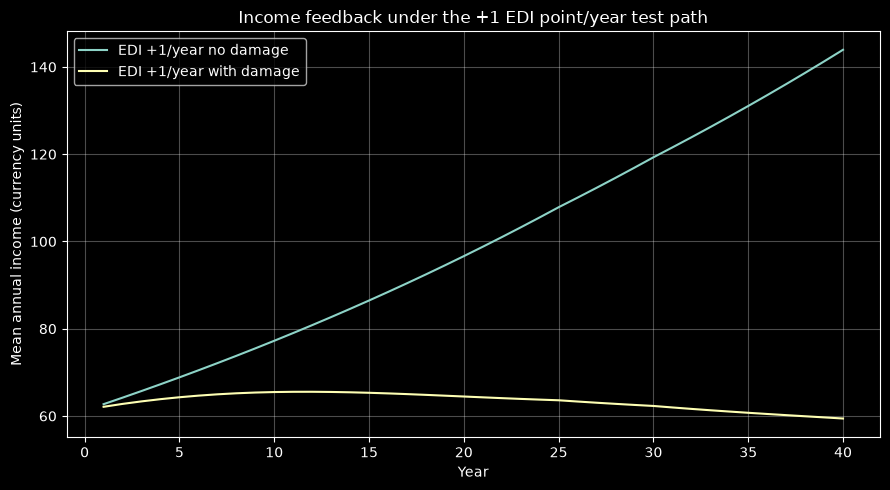

In [9]:
income_figure, income_axis = plt.subplots(figsize=(9, 5))

for result_name in ("EDI +1/year no damage", "EDI +1/year with damage"):
    result = trajectory_results[result_name]
    income_axis.plot(result["year"], result["mean_net_income"], label=result_name)

income_axis.set_xlabel("Year")
income_axis.set_ylabel("Mean annual income (currency units)")
income_axis.set_title("Income feedback under the +1 EDI point/year test path")
income_axis.grid(alpha=0.3)
income_axis.legend()
plt.tight_layout()
plt.show()

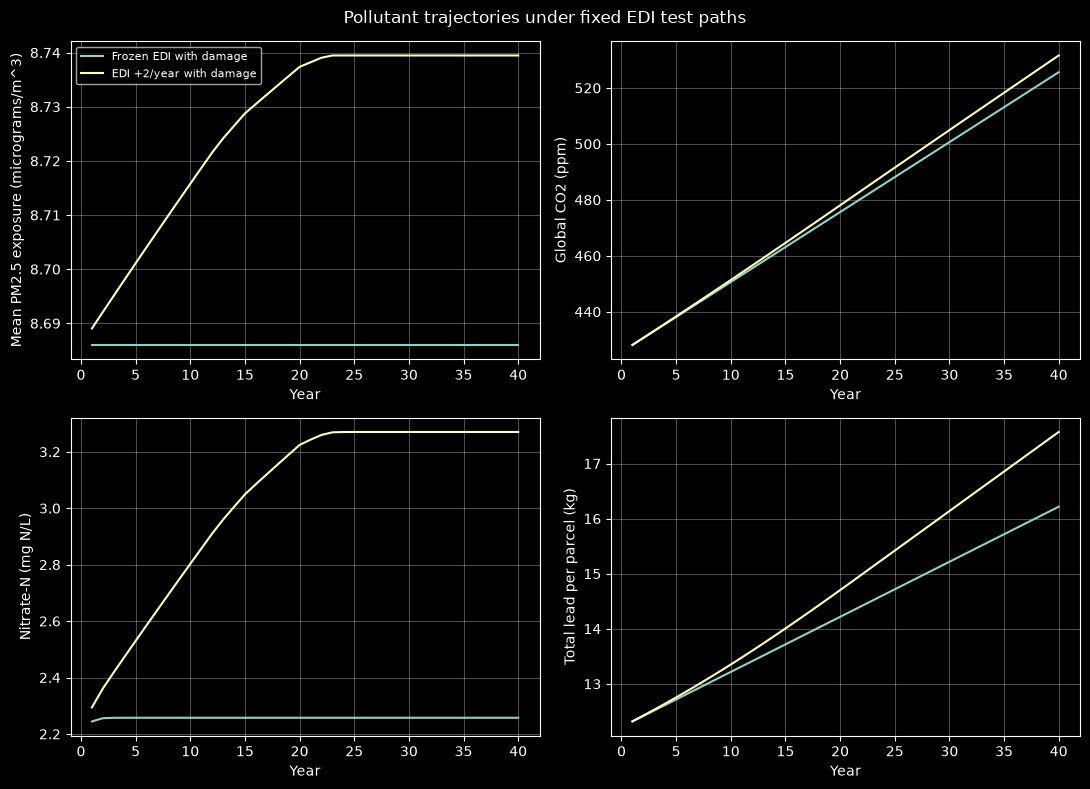

In [10]:
pollution_figure, pollution_axes = plt.subplots(2, 2, figsize=(11, 8))
pollution_metrics = (("mean_PM2.5_ug_m3", "Mean PM2.5 exposure (micrograms/m^3)"),
                     ("CO2_ppm", "Global CO2 (ppm)"), ("mean_nitrate_mg_N_L", "Nitrate-N (mg N/L)"),
                     ("mean_lead_total_kg", "Total lead per parcel (kg)"))

for axis, metric in zip(pollution_axes.flat, pollution_metrics):
    metric_name, axis_label = metric
    for result_name in ("Frozen EDI with damage", "EDI +2/year with damage"):
        result = trajectory_results[result_name]
        axis.plot(result["year"], result[metric_name], label=result_name)
    axis.set_xlabel("Year")
    axis.set_ylabel(axis_label)
    axis.grid(alpha=0.3)

pollution_axes[0, 0].legend(fontsize=8)
pollution_figure.suptitle("Pollutant trajectories under fixed EDI test paths")
plt.tight_layout()
plt.show()

## Sensitivity to damage assumptions

The table below varies one damage coefficient or lag at a time around the reference settings, using the +1 EDI point/year path. Coefficients and lag ranges are synthetic, so this shows model sensitivity rather than a confidence interval or measured economic loss.

In [11]:
damage_sensitivity_rows = []
sensitivity_factors = (("PM2.5 rate", "pm25_rate_per_ug_m3"), ("CO2 rate", "co2_rate_per_ppm"),
                       ("Nitrate-N rate", "nitrate_relative_rate"), ("Lead rate", "lead_relative_rate"),
                       ("CO2 delay", "co2_delay_years"), ("Lead delay", "lead_delay_years"))

In [12]:
no_damage_trajectory, no_damage_regions = run_damage_scenario(1.0, no_damage_settings, False)
no_damage_cumulative_income = no_damage_regions.groupby("region", sort=False)["cumulative_income"].last().mean()

for factor_name, parameter_name in sensitivity_factors:
    reference_value = reference_damage[parameter_name]
    low_value = DAMAGE_SCENARIOS["low"][parameter_name]
    high_value = DAMAGE_SCENARIOS["high"][parameter_name]
    for scenario_level, parameter_value in (("low", low_value), ("reference", reference_value), ("high", high_value)):
        settings = copy.deepcopy(reference_damage)
        settings[parameter_name] = parameter_value
        result, region_result = run_damage_scenario(1.0, settings, True)
        final_cumulative_income = region_result.groupby("region", sort=False)["cumulative_income"].last().mean()
        income_loss = no_damage_cumulative_income - final_cumulative_income
        damage_sensitivity_rows.append({
            "factor": factor_name,
            "scenario": scenario_level,
            "parameter_value": parameter_value,
            "mean_cumulative_income_loss": income_loss,
            "final_mean_damage_fraction": result.iloc[-1]["mean_damage_fraction"],
        })

In [13]:
damage_sensitivity_table = pd.DataFrame(damage_sensitivity_rows)
display(damage_sensitivity_table.round({"parameter_value": 6, "mean_cumulative_income_loss": 2, "final_mean_damage_fraction": 4}))

,factor,scenario,parameter_value,mean_cumulative_income_loss,final_mean_damage_fraction
0,PM2.5 rate,low,0.00100,1447.61,0.1220
1,PM2.5 rate,reference,0.00200,1454.35,0.1222
2,PM2.5 rate,high,0.00400,1467.77,0.1225
3,CO2 rate,low,0.00005,1402.38,0.1187
4,CO2 rate,reference,0.00010,1454.35,0.1222
5,CO2 rate,high,0.00020,1552.18,0.1291
6,Nitrate-N rate,low,0.10000,1114.32,0.0633
7,Nitrate-N rate,reference,0.25000,1454.35,0.1222
8,Nitrate-N rate,high,0.50000,1652.51,0.2028
9,Lead rate,low,0.01000,1369.64,0.1161


## Mathematical checks and limits

The checks cover reference conditions, monotonic pollutant-specific responses, lag behavior, and income bounds. In particular, the CO2 proxy needs a climate-response pathway before it can be interpreted as climate damages; regional vulnerability and overlapping health effects also need evidence before this component is used in the full environment.

In [14]:
reference_mobile = 0.01
reference_settings = DAMAGE_SCENARIOS["reference"]

reference_fractions = calculate_pollutant_damage_fractions(10.0, 10.0, 425.62, 425.62, 2.15, 2.15, reference_mobile, reference_mobile,
                                                           reference_settings)

higher_pm25 = calculate_pollutant_damage_fractions(11.0, 10.0, 425.62, 425.62, 2.15, 2.15, reference_mobile, reference_mobile,
                                                   reference_settings)["PM2.5"]
higher_co2 = calculate_pollutant_damage_fractions(10.0, 10.0, 426.62, 425.62, 2.15, 2.15, reference_mobile, reference_mobile,
                                                  reference_settings)["CO2"]
higher_nitrate = calculate_pollutant_damage_fractions(10.0, 10.0, 425.62, 425.62, 2.58, 2.15, reference_mobile, reference_mobile,
                                                      reference_settings)["Nitrate-N"]
higher_lead = calculate_pollutant_damage_fractions(10.0, 10.0, 425.62, 425.62, 2.15, 2.15, reference_mobile * 1.5, reference_mobile,
                                                   reference_settings)["Lead"]

lagged_value = update_lagged_exposure(10.0, 20.0, 5.0)
total_damage = combine_damage_fractions({"a": 0.2, "b": 0.3})
net_income = apply_income_damage(100.0, total_damage)

In [15]:
reference_check = True
for value in reference_fractions.values():
    if value != 0:
        reference_check = False

checks = [
    ("Reference pollution causes no incremental damage", reference_check),
    ("Higher PM2.5 raises PM2.5 damage", higher_pm25 > 0),
    ("Higher CO2 proxy raises CO2 damage", higher_co2 > 0),
    ("Higher nitrate raises nitrate damage", higher_nitrate > 0),
    ("Higher mobile lead raises lead damage", higher_lead > 0),
    ("Delayed exposure lies between its previous and current values", 10 < lagged_value < 20),
    ("Combined damage is below the sum of separate losses", abs(total_damage - (1 - (1 - 0.2) * (1 - 0.3))) < 1e-12),
    ("Net income is nonnegative and no greater than gross income", 0 <= net_income <= 100),
]

In [16]:
no_damage_regions = regional_results["EDI +1/year no damage"]
edi_income_elasticity = STAGE_2_SCENARIOS["income_edi_elasticity"]["reference"]

income_equation_residuals = []

for region_name, region_rows in no_damage_regions.groupby("region", sort=False):
    economic_parameters = None

    for candidate in REGIONAL_ECONOMIC_PARAMETERS:
        if candidate["region"] == region_name:
            economic_parameters = candidate
            break

    for _, row in region_rows.iterrows():
        expected_income = calculate_annual_income(economic_parameters["annual_income"], economic_parameters["annual_income_growth_rate"], row["year"], row["EDI"], economic_parameters["initial_edi"], edi_income_elasticity)

        residual = abs(expected_income - row["net_income"])
        income_equation_residuals.append(residual)

maximum_income_equation_residual = max(income_equation_residuals)
checks.append(("No-damage income matches the Stage 2 equation", maximum_income_equation_residual < 1e-10))

In [17]:
coupled_trajectory = trajectory_results["EDI +1/year with damage"]

maximum_nitrate_residual = coupled_trajectory["maximum_nitrate_mass_balance_residual_kg"].max()
maximum_lead_residual = coupled_trajectory["maximum_lead_mass_balance_residual_kg"].max()

checks.append(("Nitrate mass balance holds with changing annual inputs", maximum_nitrate_residual < 1e-5))
checks.append(("Lead mass balance holds with changing annual inputs", maximum_lead_residual < 1e-10))

checks_table = pd.DataFrame(checks, columns=["check", "passed"])

display(checks_table)

,check,passed
0,Reference pollution causes no incremental damage,True
1,Higher PM2.5 raises PM2.5 damage,True
2,Higher CO2 proxy raises CO2 damage,True
3,Higher nitrate raises nitrate damage,True
4,Higher mobile lead raises lead damage,True
5,Delayed exposure lies between its previous and...,True
6,Combined damage is below the sum of separate l...,True
7,Net income is nonnegative and no greater than ...,True
8,No-damage income matches the Stage 2 equation,True
9,Nitrate mass balance holds with changing annua...,True


In [18]:
passed_count = checks_table["passed"].sum()
total_checks = len(checks_table)

print(f"Passed {passed_count} of {total_checks} mathematical checks.")

Passed 11 of 11 mathematical checks.
